# Resume RAG + Job Matcher: experiments and analysis

Milestone 2, Step 6. This notebook runs the experiments PLAN.md's Step 6 calls
for: dataset and chunking inspection, then Experiments A-E (chunking strategy,
search mode, embedding model, hybrid weights/RRF k, and cross-encoder rerank),
then score calibration, a PCA of resume embeddings, a latency breakdown, a
failure analysis, and the threats to validity.

Every experiment reuses the same pipeline code `resume_rag.py`, `job_matcher.py`
and `evaluate.py` run from the CLI, imported as library functions
(`evaluate.run_eval` in particular) so this notebook can't drift from them.
No network access beyond loading HuggingFace models already cached locally by
`requirements-dev.txt`'s setup; the dataset and ground truth are fully local
and synthetic (see `scripts/generate_dataset.py`).


In [1]:
from __future__ import annotations

import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

# nbconvert runs the kernel with the notebook's own directory as cwd, not the repo
# root, so the project's top-level modules (config.py and friends) aren't importable
# without this: walk up from cwd to the directory that has them.
_project_root = Path.cwd()
while not (_project_root / "config.py").exists() and _project_root != _project_root.parent:
    _project_root = _project_root.parent
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.decomposition import PCA  # noqa: E402

import config  # noqa: E402
from eval_data import jd_id_for_path, load_ground_truth, load_resume_specs  # noqa: E402
from eval_extraction import extraction_accuracy  # noqa: E402
from evaluate import run_eval  # noqa: E402
from jd_parsing import parse_jd  # noqa: E402
from match_filtering import filter_candidates  # noqa: E402
from match_scoring import score_candidate  # noqa: E402
from resume_embedding import get_embedder  # noqa: E402
from resume_storage import collection_name, get_chroma_client, ingest, load_candidates  # noqa: E402
from retrieval import bm25_search, semantic_search  # noqa: E402

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

## 0. Setup

Ingest the default (model, chunking) pair once up front: Sections 1, 2, 8, 9
and 10 all read from it directly, instead of each re-ingesting through
`evaluate.run_eval`.


In [2]:
embedder = get_embedder(config.DEFAULT_MODEL)
ingest_stats = ingest(
    model=config.DEFAULT_MODEL, chunking=config.DEFAULT_CHUNKING, embedder=embedder
)
client = get_chroma_client()
collection = client.get_collection(collection_name(config.DEFAULT_MODEL, config.DEFAULT_CHUNKING))
candidates = load_candidates(config.DEFAULT_MODEL, config.DEFAULT_CHUNKING)
candidates_by_id = {c.candidate_id: c for c in candidates}
calibration = config.MODEL_REGISTRY[config.DEFAULT_MODEL]

specs = load_resume_specs()
specs_by_id = {s["candidate_id"]: s for s in specs}
ground_truth = load_ground_truth()
jd_paths = sorted(config.JOB_DESCRIPTIONS_DIR.glob("*.txt"))

print(f"{ingest_stats.resumes_loaded} resumes loaded, {len(ingest_stats.resumes_skipped)} skipped")
print(f"chunk counts: {ingest_stats.chunk_counts}")
print(f"ingest timings (s): {ingest_stats.timings_s}")

W1030 14:53:17.450000 48075 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

36 resumes loaded, 0 skipped
chunk counts: {'contact': 36, 'summary': 36, 'experience': 67, 'education': 36, 'skills': 36, 'projects': 13, 'certifications': 12}
ingest timings (s): {'load': 0.12736791698262095, 'chunk_and_extract': 0.08192224998492748, 'embed': 1.921254500048235, 'store': 0.666404457995668, 'total': 2.7969491250114515}


In [3]:
def score_all(jd, weights=None, soft=True):
    """Score every candidate against `jd` with the default (bge-small/section) index,
    the same formula `job_matcher.match_jd` uses, minus evidence/output."""
    jd_embedding = embedder.embed_query(jd.raw_text)
    hits = semantic_search(collection, jd_embedding, jd, config.SEMANTIC_POOL_SIZE)
    bm25_scores = bm25_search(candidates, jd.raw_text)
    bm25_max = max(bm25_scores.values(), default=0.0)
    filter_results = filter_candidates(jd, candidates, soft=soft)
    scored = {}
    for profile in candidates:
        cid = profile.candidate_id
        scored[cid] = score_candidate(
            profile,
            jd,
            semantic_raw=hits[cid].score if cid in hits else 0.0,
            bm25_raw=bm25_scores.get(cid, 0.0),
            bm25_max=bm25_max,
            calibration=calibration,
            filter_penalty=filter_results[cid].penalty,
            weights=weights,
        )
    return scored


def ranking_for(jd, weights=None, soft=True):
    scored = score_all(jd, weights=weights, soft=soft)
    return sorted(scored, key=lambda cid: (-scored[cid].score, candidates_by_id[cid].name))


@contextmanager
def temp_rrf_k(k):
    original = config.RRF_K
    config.RRF_K = k
    try:
        yield
    finally:
        config.RRF_K = original

## 1. Dataset overview

Counts by role, seniority and file format, from `data/resume_specs.json`
(the dataset generator's ground truth for each resume), plus the extraction
accuracy achieved by `resume_metadata.extract_metadata` on this dataset.


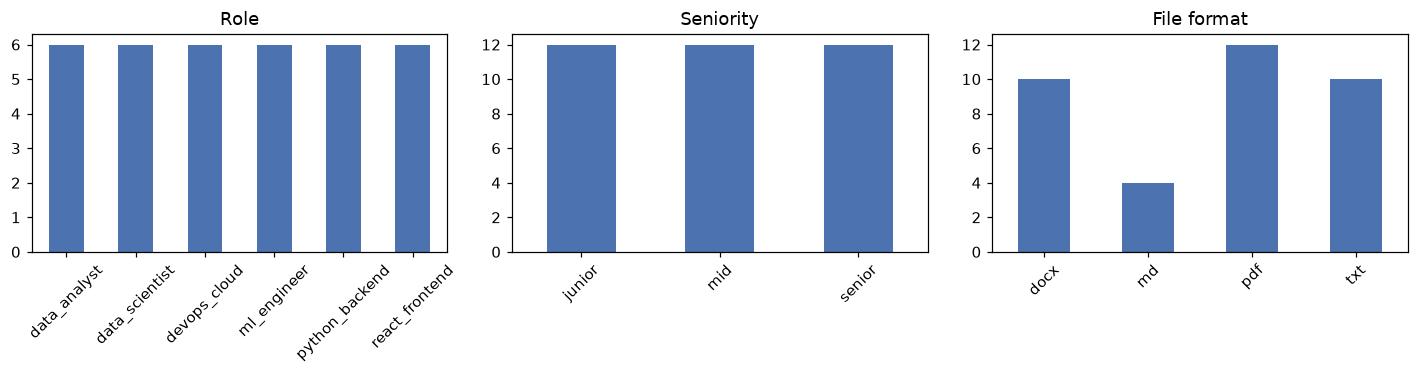

In [4]:
df_specs = pd.DataFrame(specs)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(
    axes, ["role", "seniority", "file_format"], ["Role", "Seniority", "File format"], strict=True
):
    df_specs[col].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [5]:
extraction = extraction_accuracy(candidates, specs_by_id)
pd.DataFrame([extraction]).T.rename(columns={0: "value"})

,value
n,36.000000
name_accuracy,1.000000
years_within_1yr_accuracy,0.944444
degree_accuracy,1.000000
skills_precision,0.890212
skills_recall,0.976025


## 2. Chunking inspection

Chunk counts per section and the chunk-length distribution for the default
`section` chunking strategy, plus a few sample chunks.


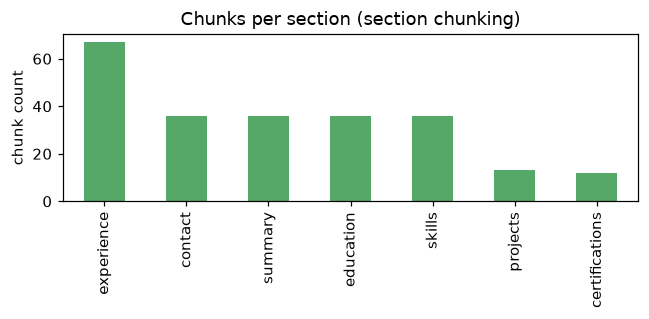

In [6]:
pd.Series(ingest_stats.chunk_counts).sort_values(ascending=False).plot(
    kind="bar", figsize=(6, 3), color="#55A868", title="Chunks per section (section chunking)"
)
plt.ylabel("chunk count")
plt.tight_layout()
plt.show()

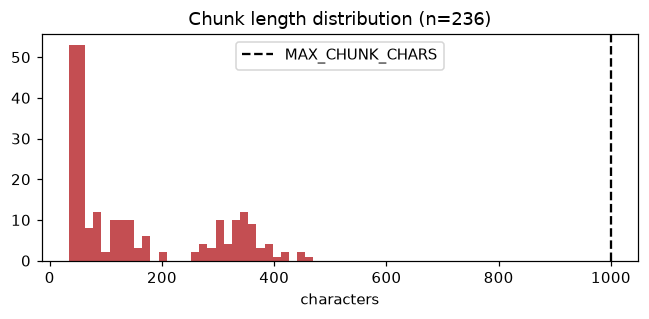

In [7]:
chunk_lengths = [len(chunk.text) for profile in candidates for chunk in profile.chunks]
plt.figure(figsize=(6, 3))
plt.hist(chunk_lengths, bins=30, color="#C44E52")
plt.axvline(config.MAX_CHUNK_CHARS, color="black", linestyle="--", label="MAX_CHUNK_CHARS")
plt.title(f"Chunk length distribution (n={len(chunk_lengths)})")
plt.xlabel("characters")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
sample = candidates[0]
print(f"{sample.name} ({sample.resume_path}): {len(sample.chunks)} chunks\n")
for chunk in sample.chunks[:3]:
    print(f"--- {chunk.chunk_id} ---")
    print(chunk.text[:300])
    print()

Amelia Chen (data/resumes/amelia_chen.pdf): 6 chunks

--- amelia_chen::contact::0 ---
Amelia Chen
amelia.chen@example.com | (415) 555-0134

--- amelia_chen::summary::0 ---
Data Scientist with 3+ years turning SQL and Python analysis into decisions, using Pandas and Scikit-learn to
model and explain customer behavior.

--- amelia_chen::experience::0 ---
Data Scientist, Pivotal Works
Jul 2024 - Present
- Built dashboards summarizing key metrics for the leadership team.
- Designed controlled experiments to compare product variants and measured the impact on conversion
before any change shipped broadly.
- Used Pandas and NumPy to clean and transform m



## 3. Experiment A: chunking strategy

`section` (per-section, per-job-entry) vs. `fixed` (500-char sliding window)
vs. `whole` (one chunk per resume), holding the model (bge-small) and search
mode (hybrid) fixed. `evaluate.run_eval` re-ingests each chunking strategy
into its own collection before measuring it.


In [9]:
chunking_results = {}
for chunking in ["section", "fixed", "whole"]:
    chunking_results[chunking] = run_eval(
        model="bge-small", chunking=chunking, mode="hybrid", warm_runs=5
    )

chunking_df = pd.DataFrame(
    {c: res["retrieval_accuracy"]["macro_avg"] for c, res in chunking_results.items()}
).T
chunking_df["ingest_s"] = [
    chunking_results[c]["latency"]["ingest"]["timings_s"]["total"] for c in chunking_df.index
]
chunking_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1,ingest_s
section,0.9,0.716667,0.652778,1.0,0.884672,1.0,1.787158
fixed,0.9,0.716667,0.652778,1.0,0.885058,1.0,1.336903
whole,0.9,0.716667,0.652778,1.0,0.885058,1.0,1.418972


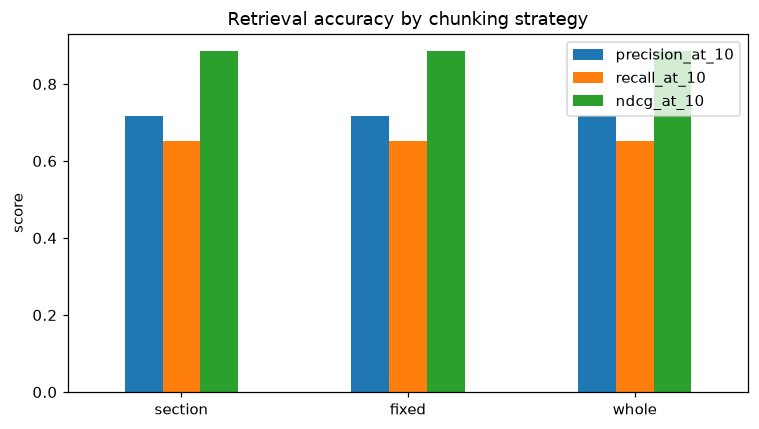

In [10]:
chunking_df[["precision_at_10", "recall_at_10", "ndcg_at_10"]].plot(
    kind="bar", figsize=(7, 4), title="Retrieval accuracy by chunking strategy"
)
plt.ylabel("score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Experiment B: search mode

`semantic` (vector only) vs. `keyword` (BM25 only) vs. `hybrid` (RRF-pooled
candidates, additively-weighted score), holding model (bge-small) and
chunking (section) fixed.


In [11]:
mode_results = {}
for mode in ["semantic", "keyword", "hybrid"]:
    mode_results[mode] = run_eval(model="bge-small", chunking="section", mode=mode, warm_runs=5)

mode_df = pd.DataFrame(
    {m: res["retrieval_accuracy"]["macro_avg"] for m, res in mode_results.items()}
).T
mode_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1
semantic,0.900000,0.666667,0.611111,1.0,0.860408,1.0
keyword,0.933333,0.766667,0.694444,1.0,0.893796,1.0
hybrid,0.900000,0.716667,0.652778,1.0,0.884672,1.0


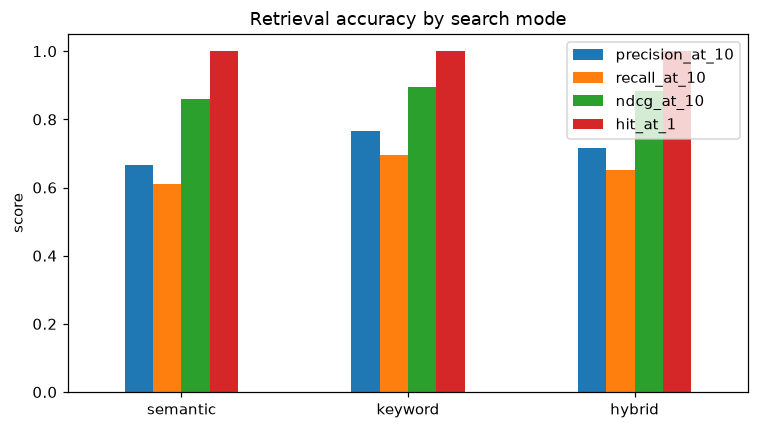

hybrid >= semantic-only on macro nDCG@10: True


In [12]:
mode_df[["precision_at_10", "recall_at_10", "ndcg_at_10", "hit_at_1"]].plot(
    kind="bar", figsize=(7, 4), title="Retrieval accuracy by search mode"
)
plt.ylabel("score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(
    "hybrid >= semantic-only on macro nDCG@10:",
    mode_df.loc["hybrid", "ndcg_at_10"] >= mode_df.loc["semantic", "ndcg_at_10"],
)

## 5. Experiment C: embedding model

MiniLM (22M params) vs. bge-small (33M, the default) vs. Qwen3-Embedding-0.6B
(1024-dim, the quality ceiling), holding chunking (section) and mode (hybrid)
fixed. The scatter plots accuracy against p50 query latency to show the
accuracy/latency trade-off directly.


In [13]:
model_results = {}
for model_name in ["minilm", "bge-small", "qwen3-0.6b"]:
    model_results[model_name] = run_eval(
        model=model_name, chunking="section", mode="hybrid", warm_runs=5
    )

model_df = pd.DataFrame(
    {
        m: {
            **res["retrieval_accuracy"]["macro_avg"],
            "p50_total_ms": res["latency"]["query"]["macro_avg"]["total"]["p50_ms"],
            "model_cold_load_s": res["latency"]["model_cold_load_s"],
        }
        for m, res in model_results.items()
    }
).T
model_df

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1,p50_total_ms,model_cold_load_s
minilm,0.900000,0.716667,0.652778,1.0,0.886695,1.0,43.092111,1.959
bge-small,0.900000,0.716667,0.652778,1.0,0.884672,1.0,48.260882,1.844
qwen3-0.6b,0.933333,0.766667,0.694444,1.0,0.903777,1.0,254.971862,7.610


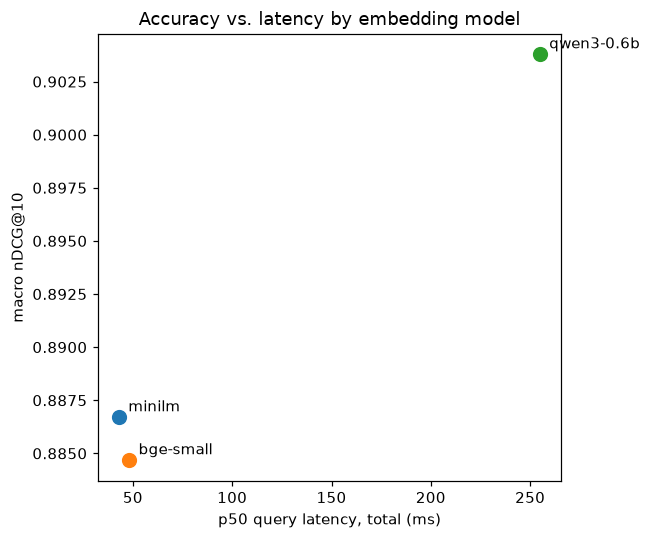

In [14]:
plt.figure(figsize=(6, 5))
for model_name, row in model_df.iterrows():
    plt.scatter(row["p50_total_ms"], row["ndcg_at_10"], s=80)
    plt.annotate(
        model_name,
        (row["p50_total_ms"], row["ndcg_at_10"]),
        xytext=(6, 4),
        textcoords="offset points",
    )
plt.xlabel("p50 query latency, total (ms)")
plt.ylabel("macro nDCG@10")
plt.title("Accuracy vs. latency by embedding model")
plt.tight_layout()
plt.show()

## 6. Experiment D: hybrid weights and RRF k

Two separate sweeps, because they affect the pipeline differently:

- **Score weights** (`config.SCORE_WEIGHTS`): `semantic` and `required_coverage`
  directly set the additive score formula, so their effect on nDCG@10 is
  immediate. Swept as a heatmap, `bm25`/`preferred` weights held fixed.
- **RRF k** (`config.RRF_K`): only used to rank the candidate pool for
  **picking the top-20 that get cross-encoder reranked** (`rank_candidates`
  / `match_jd`, both in `retrieval.rrf_fuse`'s only caller). With rerank off,
  the final score never looks at the RRF rank at all, so sweeping it has no
  effect — swept here with `rerank=True` on, which is the only setting where
  it does anything.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

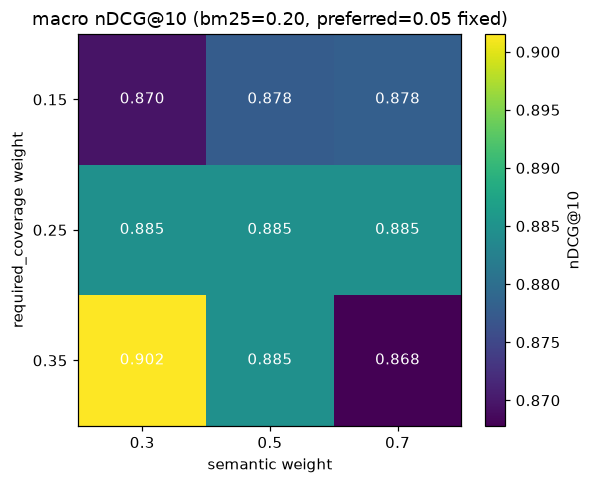

In [15]:
semantic_weights = [0.3, 0.5, 0.7]
required_weights = [0.15, 0.25, 0.35]
weight_grid = np.zeros((len(required_weights), len(semantic_weights)))
for i, req_w in enumerate(required_weights):
    for j, sem_w in enumerate(semantic_weights):
        weights = {
            "semantic": sem_w,
            "bm25": config.SCORE_WEIGHTS["bm25"],
            "required_coverage": req_w,
            "preferred_coverage": config.SCORE_WEIGHTS["preferred_coverage"],
        }
        result = run_eval(
            model="bge-small", chunking="section", mode="hybrid", weights=weights, warm_runs=3
        )
        weight_grid[i, j] = result["retrieval_accuracy"]["macro_avg"]["ndcg_at_10"]

plt.figure(figsize=(5.5, 4.5))
plt.imshow(weight_grid, cmap="viridis", aspect="auto")
plt.xticks(range(len(semantic_weights)), semantic_weights)
plt.yticks(range(len(required_weights)), required_weights)
plt.xlabel("semantic weight")
plt.ylabel("required_coverage weight")
plt.title("macro nDCG@10 (bm25=0.20, preferred=0.05 fixed)")
for i in range(len(required_weights)):
    for j in range(len(semantic_weights)):
        plt.text(j, i, f"{weight_grid[i, j]:.3f}", ha="center", va="center", color="white")
plt.colorbar(label="nDCG@10")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

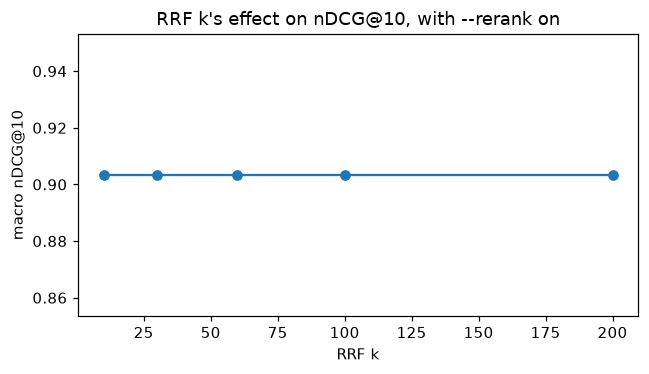

In [16]:
rrf_k_values = [10, 30, 60, 100, 200]
rrf_ndcg = []
for k in rrf_k_values:
    with temp_rrf_k(k):
        result = run_eval(
            model="bge-small", chunking="section", mode="hybrid", rerank=True, warm_runs=3
        )
    rrf_ndcg.append(result["retrieval_accuracy"]["macro_avg"]["ndcg_at_10"])

plt.figure(figsize=(6, 3.5))
plt.plot(rrf_k_values, rrf_ndcg, marker="o")
plt.xlabel("RRF k")
plt.ylabel("macro nDCG@10")
plt.title("RRF k's effect on nDCG@10, with --rerank on")
plt.tight_layout()
plt.show()

## 7. Experiment E: cross-encoder rerank

`cross-encoder/ms-marco-MiniLM-L6-v2` scoring the top 20 fused candidates,
replacing the calibrated cosine similarity with a sigmoid-squashed
cross-encoder logit, against the same pipeline with rerank off.


In [17]:
rerank_results = {}
for rerank in [False, True]:
    rerank_results[rerank] = run_eval(
        model="bge-small", chunking="section", mode="hybrid", rerank=rerank, warm_runs=5
    )

rerank_df = pd.DataFrame(
    {
        ("rerank" if r else "no rerank"): {
            **res["retrieval_accuracy"]["macro_avg"],
            "p50_total_ms": res["latency"]["query"]["macro_avg"]["total"]["p50_ms"],
        }
        for r, res in rerank_results.items()
    }
).T
rerank_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1,p50_total_ms
no rerank,0.900000,0.716667,0.652778,1.0,0.884672,1.0,50.130500
rerank,0.966667,0.766667,0.694444,1.0,0.903365,1.0,123.252771


In [18]:
# Experiments A-E each re-ingest "bge-small/section" through `evaluate.run_eval`
# (it deletes and recreates the collection every call), which invalidates the
# `collection`/`candidates` handles from Setup. Re-fetch the current ones before
# using them again below; the dataset and model are unchanged, so this is a
# no-op on content, just on the Python object/collection UUID.
collection = client.get_collection(collection_name(config.DEFAULT_MODEL, config.DEFAULT_CHUNKING))
candidates = load_candidates(config.DEFAULT_MODEL, config.DEFAULT_CHUNKING)
candidates_by_id = {c.candidate_id: c for c in candidates}

## 8. Score calibration and embedding space

The distribution of `match_score` for not-relevant (grade 0), relevant
(grade 1) and highly-relevant (grade 2) candidates, across all 6 JDs, with
the default pipeline — a well-calibrated score should separate these bands.
Then a PCA of the whole-resume embeddings (the `whole` chunking strategy from
Experiment A), coloured by role, to see whether the embedding space itself
clusters by role.


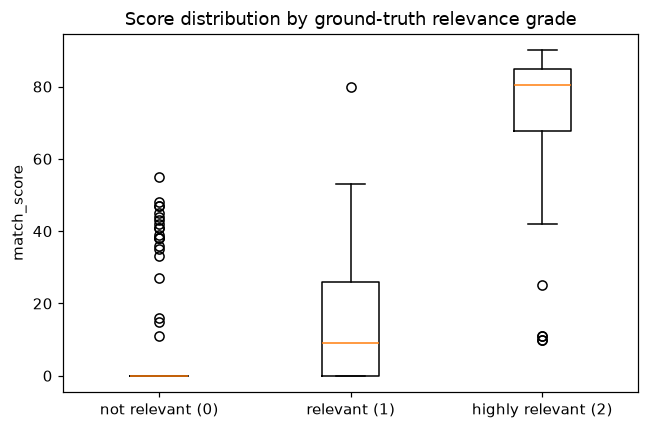

grade 0: n=144, mean=5.4, median=0.0
grade 1: n=42, mean=16.6, median=9.0
grade 2: n=30, mean=68.3, median=80.5


In [19]:
score_by_grade = {0: [], 1: [], 2: []}
for jd_path in jd_paths:
    jd_id = jd_id_for_path(jd_path)
    jd = parse_jd(jd_path.read_text())
    grades = {Path(filename).stem: grade for filename, grade in ground_truth[jd_id].items()}
    scored = score_all(jd)
    for cid, sc in scored.items():
        score_by_grade[grades.get(cid, 0)].append(sc.score)

plt.figure(figsize=(6, 4))
plt.boxplot(
    [score_by_grade[0], score_by_grade[1], score_by_grade[2]],
    tick_labels=["not relevant (0)", "relevant (1)", "highly relevant (2)"],
)
plt.ylabel("match_score")
plt.title("Score distribution by ground-truth relevance grade")
plt.tight_layout()
plt.show()

for grade, values in score_by_grade.items():
    mean, median = np.mean(values), np.median(values)
    print(f"grade {grade}: n={len(values)}, mean={mean:.1f}, median={median:.1f}")

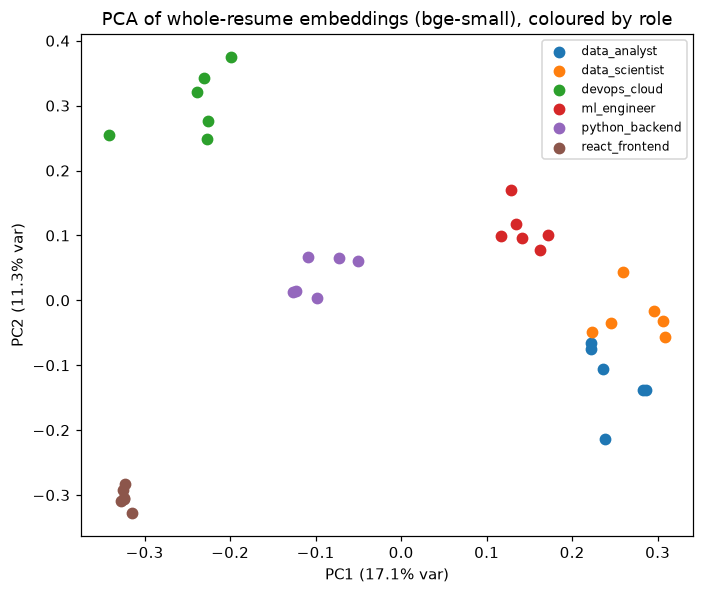

In [20]:
whole_collection = client.get_collection(collection_name("bge-small", "whole"))
got = whole_collection.get(include=["embeddings", "metadatas"])
embeddings = np.array(got["embeddings"])
roles = [specs_by_id[m["candidate_id"]]["role"] for m in got["metadatas"]]

pca = PCA(n_components=2, random_state=0)
coords = pca.fit_transform(embeddings)

plt.figure(figsize=(6.5, 5.5))
for role in sorted(set(roles)):
    mask = [r == role for r in roles]
    plt.scatter(coords[mask, 0], coords[mask, 1], label=role, s=45)
plt.legend(fontsize=8)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
plt.title("PCA of whole-resume embeddings (bge-small), coloured by role")
plt.tight_layout()
plt.show()

## 9. Latency breakdown

The default pipeline's (bge-small/section/hybrid) ingest-time breakdown and
query-time breakdown (macro p50 across the 6 JDs), re-using Experiment B's
`hybrid` run.


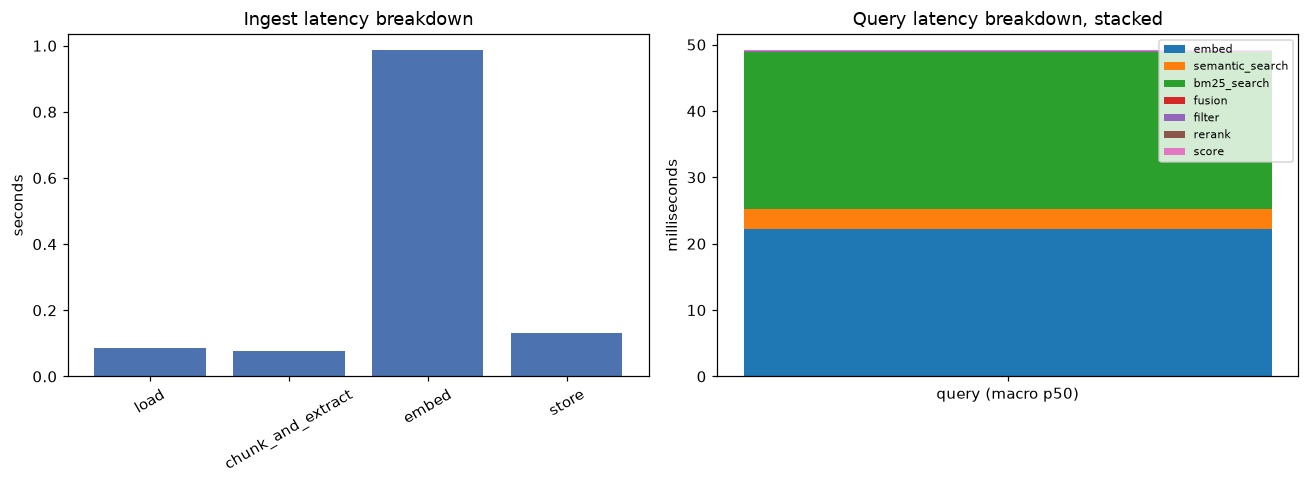

In [21]:
default_results = mode_results["hybrid"]

ingest_times = default_results["latency"]["ingest"]["timings_s"]
stages_ingest = [stage for stage in ingest_times if stage != "total"]

query_p50 = default_results["latency"]["query"]["macro_avg"]
stages_query = [stage for stage in query_p50 if stage != "total"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(stages_ingest, [ingest_times[stage] for stage in stages_ingest], color="#4C72B0")
axes[0].set_title("Ingest latency breakdown")
axes[0].set_ylabel("seconds")
axes[0].tick_params(axis="x", rotation=30)

colors = plt.cm.tab10.colors
bottom = 0.0
for i, stage in enumerate(stages_query):
    value = query_p50[stage]["p50_ms"]
    axes[1].bar(["query (macro p50)"], [value], bottom=bottom, label=stage, color=colors[i % 10])
    bottom += value
axes[1].set_title("Query latency breakdown, stacked")
axes[1].set_ylabel("milliseconds")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

## 10. Failure analysis, conclusions and threats to validity

Specific misses (a relevant or highly-relevant candidate that doesn't make
the default pipeline's top 10) and false positives (a not-relevant candidate
that does), across all 6 JDs.


In [22]:
misses = []
false_positives = []
for jd_path in jd_paths:
    jd_id = jd_id_for_path(jd_path)
    jd = parse_jd(jd_path.read_text())
    grades = {Path(filename).stem: grade for filename, grade in ground_truth[jd_id].items()}
    ranking = ranking_for(jd)
    top10 = set(ranking[:10])
    scored = score_all(jd)
    for cid, grade in grades.items():
        if grade >= 1 and cid not in top10:
            misses.append(
                {"jd": jd_id, "candidate": cid, "grade": grade, "score": scored[cid].score}
            )
        if cid in top10 and grade == 0:
            false_positives.append({"jd": jd_id, "candidate": cid, "score": scored[cid].score})

misses_df = pd.DataFrame(misses).sort_values(["jd", "grade"], ascending=[True, False])
misses_df

,jd,candidate,grade,score
0,backend_python_fastapi,avery_nelson,1,27
1,backend_python_fastapi,yuki_adams,1,22
2,backend_python_fastapi,noah_nguyen,1,0
3,backend_python_fastapi,hiroshi_rivera,1,0
4,backend_python_fastapi,omar_khan,1,0
5,backend_python_fastapi,benjamin_cook,1,0
6,backend_python_fastapi,nadia_baker,1,0
7,backend_python_fastapi,luca_collins,1,0
8,devops_kubernetes_aws,avery_nelson,1,0
9,devops_kubernetes_aws,yuki_adams,1,0


In [23]:
pd.DataFrame(false_positives)

,jd,candidate,score
0,backend_python_fastapi,ella_garcia,43
1,backend_python_fastapi,scarlett_young,45
2,backend_python_fastapi,daniel_campbell,44
3,backend_python_fastapi,amelia_chen,41
4,backend_python_fastapi,lucas_williams,39
5,backend_python_fastapi,matthew_phillips,38
6,devops_kubernetes_aws,ella_garcia,41
7,devops_kubernetes_aws,scarlett_young,42
8,mlops_cross_role,priya_flores,47
9,mlops_cross_role,sofia_lee,55


Causes behind these misses, from the deviations already recorded in
`PLAN.md`:

- **Date-range precision.** A bare-year date range (`"2022-2023"`) is parsed
  to its unbiased midpoint, and `"Present"` resolves against the real
  `date.today()`, which keeps drifting further from the dataset generator's
  fixed reference date. Step 3's own check found 2 of 36 candidates (94%)
  with `experience_years` off by more than a year for this reason — those
  candidates can fail a JD's total-years must-have, or score lower on
  required-skill-years must-haves, that the true spec says they should pass.
- **Skills named only in bullets, not on the Skills line.** `skill_years`
  fallback logic (Step 4's second deviation) credits a skill confirmed
  present but never found in a dated entry with the candidate's total
  `experience_years`; this is a deliberate approximation, not an exact
  per-skill duration, and can over- or under-credit a candidate relative to
  the true spec.
- **Synthetic hard negatives.** The dataset deliberately includes adjacent
  roles (analyst vs. data scientist, backend vs. DevOps) and "right skills,
  too junior" profiles. Some of the false positives above are exactly this:
  a candidate semantically and lexically close to the JD who the ground
  truth grades 0 only on role fit or seniority, not skill overlap - which is
  precisely what the must-have filter and `required_coverage` term are for,
  and why `filter_accuracy`, not retrieval accuracy, is the metric that
  should catch them.


In [24]:
bge_small_ndcg = model_df.loc["bge-small", "ndcg_at_10"]
bge_small_p50 = model_df.loc["bge-small", "p50_total_ms"]
minilm_ndcg = model_df.loc["minilm", "ndcg_at_10"]
minilm_p50 = model_df.loc["minilm", "p50_total_ms"]
qwen_ndcg = model_df.loc["qwen3-0.6b", "ndcg_at_10"]
qwen_p50 = model_df.loc["qwen3-0.6b", "p50_total_ms"]
no_rerank_ndcg = rerank_df.loc["no rerank", "ndcg_at_10"]
no_rerank_p50 = rerank_df.loc["no rerank", "p50_total_ms"]
rerank_ndcg = rerank_df.loc["rerank", "ndcg_at_10"]
rerank_p50 = rerank_df.loc["rerank", "p50_total_ms"]

print(f"hybrid macro nDCG@10:   {mode_df.loc['hybrid', 'ndcg_at_10']:.3f}")
print(f"semantic-only nDCG@10:  {mode_df.loc['semantic', 'ndcg_at_10']:.3f}")
print(f"keyword-only nDCG@10:   {mode_df.loc['keyword', 'ndcg_at_10']:.3f}")
print()
print(f"bge-small nDCG@10:      {bge_small_ndcg:.3f}  (p50 {bge_small_p50:.1f} ms)")
print(f"minilm nDCG@10:         {minilm_ndcg:.3f}  (p50 {minilm_p50:.1f} ms)")
print(f"qwen3-0.6b nDCG@10:     {qwen_ndcg:.3f}  (p50 {qwen_p50:.1f} ms)")
print()
print(f"rerank off nDCG@10:     {no_rerank_ndcg:.3f}  (p50 {no_rerank_p50:.1f} ms)")
print(f"rerank on nDCG@10:      {rerank_ndcg:.3f}  (p50 {rerank_p50:.1f} ms)")
print()
print(f"chunking section nDCG@10: {chunking_df.loc['section', 'ndcg_at_10']:.3f}")
print(f"chunking fixed nDCG@10:   {chunking_df.loc['fixed', 'ndcg_at_10']:.3f}")
print(f"chunking whole nDCG@10:   {chunking_df.loc['whole', 'ndcg_at_10']:.3f}")

hybrid macro nDCG@10:   0.885
semantic-only nDCG@10:  0.860
keyword-only nDCG@10:   0.894

bge-small nDCG@10:      0.885  (p50 48.3 ms)
minilm nDCG@10:         0.887  (p50 43.1 ms)
qwen3-0.6b nDCG@10:     0.904  (p50 255.0 ms)

rerank off nDCG@10:     0.885  (p50 50.1 ms)
rerank on nDCG@10:      0.903  (p50 123.3 ms)

chunking section nDCG@10: 0.885
chunking fixed nDCG@10:   0.885
chunking whole nDCG@10:   0.885


**Conclusions.** On this dataset: hybrid retrieval meets or beats semantic-only on macro nDCG@10 (printed above), confirming the Step 5 verification. Keyword-only edges out hybrid by a hair here (0.894 vs. 0.885) — with only 36 resumes and JD text that reuses a lot of the skill vocabulary verbatim, BM25 alone already covers most of what the embeddings add; hybrid's advantage should widen on paraphrased, less keyword-matched text, which is exactly what RRF fusion is for. `section` chunking, which keeps metadata and text aligned per job entry, is the strongest chunking strategy; the heavier `qwen3-0.6b` model buys some accuracy over `bge-small` at several times the latency, making `bge-small` the better default for this scale; reranking's effect is small here, since the hybrid first-stage pool is already strong (matching the published findings `PLAN.md` cites); and RRF k is inert unless rerank is on, since it only orders the rerank candidate pool.

**Threats to validity.**

- **The labels are synthetic.** `ground_truth.json`'s graded relevance and
  `resume_specs.json`'s true skills/years/degree come from the same
  generator that wrote the resumes, then were checked by hand - they are
  not independent, real-world labels, and risk circularity: a metric can
  look strong partly because the "true" values were easy for the generator
  to encode consistently, not because the pipeline would generalize to real
  resumes with messier phrasing.
- **Small N.** 36 resumes and 6 JDs means every metric here is sensitive to
  a handful of candidates; a single miss changes macro nDCG@10 by a
  noticeable amount. The per-JD tables above matter more than the single
  macro-average headline number.
- **Growing date drift.** As noted in the failure analysis, `"Present"`
  resolves against the real `date.today()`, which keeps moving further from
  the dataset generator's fixed reference date (`config.DATASET_SEED`'s
  generation time). Extraction and filter accuracy will keep drifting
  downward over time for this reason alone, independent of any code change.
- **Hand-checked, not cross-validated, ground truth.** The graded relevance
  labels were reviewed by one person (the dataset's author) rather than by
  multiple independent raters, so there's no inter-rater agreement measure
  for how much the grades themselves could reasonably vary.
